# 01 - Initial Data Inspection (lean version)

**Project:** Delhi Climate-Aware Smart Grid Demand Forecasting
**Roadmap phase:** Phase 3 - Inspect the raw data before cleaning

**Goal:** run only the sanity checks that change a decision, and write down what we found. This notebook only *looks* at the raw data. It does not clean or modify it.

**Checks in this notebook**
1. Size, columns and time range
2. Duplicate timestamps and missing values
3. Missing 5-minute steps and long gaps
4. Unit and plausibility of `Power demand`
5. Columns that leak the target or are not needed
6. One overview plot
7. A list of suspicious dates (investigated in notebook 02)

Everything else (patterns, weather relationships, cleaning decisions, features) belongs to notebook 02.

## 0. Imports and loading the data

In [72]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Change this to the name of your CSV file
FILE_PATH = "../data/raw/powerdemand_5min_2021_to_2024_with weather.csv"

# folders for the files this notebook saves
os.makedirs("../reports/figures", exist_ok=True)

df = pd.read_csv(FILE_PATH)
print("Loaded:", FILE_PATH)

Loaded: ../data/raw/powerdemand_5min_2021_to_2024_with weather.csv


**Column meanings (from the Kaggle Data Card)**

| Column | Meaning | Unit |
|---|---|---|
| `datetime` | Timestamp of the observation | - |
| `Power demand` | Electricity demand every 5 minutes (**our target**) | Kaggle says kW (checked below) |
| `temp`, `dwpt`, `rhum`, `wdir`, `wspd`, `pres` | Observed weather: temperature, dew point, humidity, wind direction, wind speed, pressure | °C, °C, %, degrees, m/s, hPa |
| `year`, `month`, `day`, `hour`, `minute` | Parts of the timestamp | - |
| `moving_avg_3` | 3-step moving average of power demand | same as target |

## 1. Size, columns and time range

In [73]:
print("Shape (rows, columns):", df.shape)
print("Columns:", list(df.columns))
df.head()

Shape (rows, columns): (393440, 15)
Columns: ['Unnamed: 0', 'datetime', 'Power demand', 'temp', 'dwpt', 'rhum', 'wdir', 'wspd', 'pres', 'year', 'month', 'day', 'hour', 'minute', 'moving_avg_3']


,Unnamed: 0,datetime,Power demand,temp,dwpt,rhum,wdir,wspd,pres,year,month,day,hour,minute,moving_avg_3
0,0,2021-01-01 00:30:00,2014.00,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,30,NaN
1,1,2021-01-01 00:35:00,2005.63,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,35,NaN
2,2,2021-01-01 00:40:00,1977.60,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,40,1999.076667
3,3,2021-01-01 00:45:00,1976.44,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,45,1986.556667
4,4,2021-01-01 00:50:00,1954.37,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,50,1969.470000


In [74]:
# datetime was loaded as text, so convert it to a real datetime
df["datetime"] = pd.to_datetime(df["datetime"])

# make sure rows are in time order
print("Already sorted?", df["datetime"].is_monotonic_increasing)
df = df.sort_values("datetime").reset_index(drop=True)

print("First timestamp:", df["datetime"].min())
print("Last timestamp: ", df["datetime"].max())

Already sorted? True
First timestamp: 2021-01-01 00:30:00
Last timestamp:  2024-12-12 00:30:00


**Assumption for the data register:** the source does not say whether a timestamp marks the start or the end of its 5-minute interval, or which timezone it uses. The unit check below suggests local time (IST). We record the interval convention as **unknown but consistent**. A 5-minute shift does not matter for hourly forecasting.

## 2. Duplicates and missing values

In [75]:
print("Duplicated timestamps:", df["datetime"].duplicated().sum())

# missing values, only for columns that have any
missing = df.isna().sum()
print()
print("Missing values per column:")
print(missing[missing > 0])

Duplicated timestamps: 0

Missing values per column:
wdir            540
moving_avg_3      2
dtype: int64


`wdir` has missing values, but wind direction is not in our planned features. `moving_avg_3` is missing only in the first rows, because a moving average needs earlier rows.
The target `Power demand` has no empty cells, **but** that does not mean no time steps are missing. That is checked next.

## 3. Time grid: missing 5-minute steps and long gaps

In [76]:
# how many rows should there be if no 5-minute step were missing?
first = df["datetime"].min()
last = df["datetime"].max()
expected_rows = int((last - first) / pd.Timedelta(minutes=5)) + 1
missing_steps = expected_rows - len(df)

print("Expected rows:", expected_rows)
print("Actual rows:  ", len(df))
print("Missing 5-min steps:", missing_steps, "(" + str(round(missing_steps / expected_rows * 100, 1)) + "%)")

Expected rows: 415009
Actual rows:   393440
Missing 5-min steps: 21569 (5.2%)


In [77]:
# time between each row and the one before it
step = df["datetime"].diff()
print("Most common step sizes:")
print(step.value_counts().head(5))

# gaps longer than 1 hour: when they start, when they end, how long they are
is_long = step > pd.Timedelta(hours=1)
long_gaps = pd.DataFrame({
    "gap_start": df["datetime"].shift(1)[is_long],   # last row before the gap
    "gap_end": df["datetime"][is_long],              # first row after the gap
    "length": step[is_long],
}).sort_values("length", ascending=False)

print()
print("Gaps longer than 1 hour:", len(long_gaps))
print("Longest gap:", long_gaps["length"].max())
long_gaps.head(10)

Most common step sizes:
datetime
0 days 00:05:00    392289
0 days 00:10:00       272
0 days 00:15:00       267
0 days 00:20:00        93
0 days 01:20:00        52
Name: count, dtype: int64

Gaps longer than 1 hour: 368
Longest gap: 2 days 10:05:00


,gap_start,gap_end,length
55378,2021-07-19 13:55:00,2021-07-22,2 days 10:05:00
77166,2021-10-09 23:50:00,2021-10-12,2 days 00:10:00
153410,2022-07-22 12:05:00,2022-07-24,1 days 11:55:00
106039,2022-01-25 19:50:00,2022-01-27,1 days 04:10:00
110535,2022-02-12 21:15:00,2022-02-14,1 days 02:45:00
115731,2022-03-04 22:45:00,2022-03-06,1 days 01:15:00
299175,2023-12-31 22:45:00,2024-01-02,1 days 01:15:00
93264,2021-12-08 23:35:00,2021-12-10,1 days 00:25:00
68979,2021-09-09 23:45:00,2021-09-11,1 days 00:15:00
315114,2024-02-29 23:45:00,2024-03-02,1 days 00:15:00


In [78]:
# save the gap list for the next notebook
long_gaps.to_csv("../reports/long_gaps.csv", index=False)

Several of the longest gaps end on the 2nd of a month, which means the whole 1st of that month is missing. Whatever the cause, these are gaps in the source data. We keep them as missing hours and do **not** fill them (decision for notebook 02).

## 4. Unit and plausibility of `Power demand`

In [79]:
# summary of the target
print(df["Power demand"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(1))

count    393440.0
mean       3960.7
std        1300.5
min        1302.1
1%         1545.0
5%         1818.8
50%        3832.3
95%        6206.1
99%        7048.8
max        8631.5
Name: Power demand, dtype: float64


In [80]:
# highest reading in each year, with its timestamp
yearly_peak = df.loc[df.groupby(df["datetime"].dt.year)["Power demand"].idxmax(), ["datetime", "Power demand"]]
yearly_peak

,datetime,Power demand
10707,2021-02-07 15:15:00,7292.33
147381,2022-06-29 15:05:00,7673.23
262341,2023-08-22 15:15:00,7409.94
344780,2024-06-19 15:05:00,8631.53


**Unit:** Kaggle says kW, but the values are about 1,300 to 8,600. As kW this would be a few MW, which is not Delhi's demand. As **MW** it fits Delhi.

**Check against reported peaks** (news reports of SLDC data): 2021: 7,323 MW. 2022: 7,695 MW. 2023: 7,438 MW. 
2024: 8,656 MW. 
The 2024 maximum is almost the same value, at 15:05 on the same day. So the unit is **MW**, and the timestamps look like local time with no hour shift.  
5-minute readings can be slightly below an instantaneous peak, so a small gap (well under 1%) is expected.

## 5. Columns that leak the target or are not needed

In [81]:
# Is moving_avg_3 just the average of the last 3 target values, including the current one?
rolling_3 = df["Power demand"].rolling(3).mean()
print("Largest difference from a 3-row rolling mean of the target:", (df["moving_avg_3"] - rolling_3).abs().max())

Largest difference from a 3-row rolling mean of the target: 0.0


A difference of 0 (or a tiny rounding value such as 1e-12) means `moving_avg_3` is built from the current target value, so it **leaks the target**. Drop it.
`Unnamed: 0` is just the old row index. `year`, `month`, `day`, `hour` and `minute` repeat the timestamp, so we can safely drop them and rebuild calendar features from `datetime` later.

## 6. An overview plot

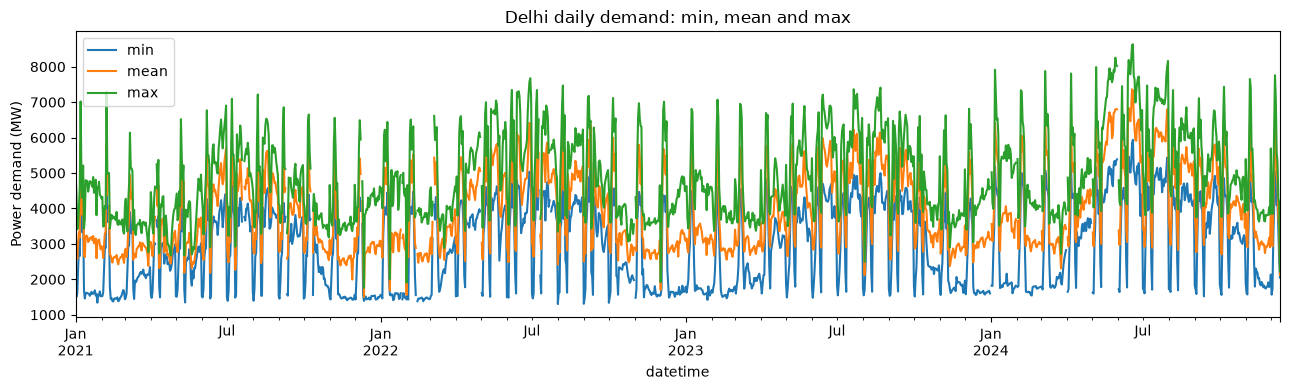

In [82]:
# daily minimum, mean and maximum of demand
daily = df.set_index("datetime")["Power demand"].resample("D").agg(["min", "mean", "max"])

daily.plot(figsize=(13, 4), title="Delhi daily demand: min, mean and max")
plt.ylabel("Power demand (MW)")
plt.tight_layout()
plt.savefig("../reports/figures/daily_demand_overview.png", dpi=150)
plt.show()

Read this plot for: the seasonal pattern (summer peaks), flat or empty stretches where data is missing, and odd days where the maximum or mean drops far below the days around it.

## 7. Suspicious dates (to investigate in notebook 02)

In [83]:
# Hot weather (temp above 30) but low demand (below 2,000 MW) looks odd.
# This only LISTS the dates. Notebook 02 decides what they are.

low = df[(df["Power demand"] < 2000) & (df["temp"] > 30)]
print("Rows that match:", len(low))

# how many such rows per day
low_per_day = low.groupby(low["datetime"].dt.date).size().sort_values(ascending=False)
print("Days with at least one such row:", len(low_per_day))
low_per_day.head(15)

Rows that match: 1340
Days with at least one such row: 46


datetime
2021-07-02    80
2021-07-11    78
2022-06-03    73
2021-07-01    69
2022-05-12    66
2022-06-12    64
2022-05-03    63
2024-06-03    59
2023-09-02    54
2022-06-02    50
2024-06-12    50
2024-07-02    50
2024-06-02    49
2021-06-12    42
2022-06-01    42
dtype: int64

In [84]:
# save the list for the next notebook
low_per_day.rename("low_rows").to_csv("../reports/low_demand_hot_days.csv", index_label="date")

**Note from the first run:** the top dates (2021-07-01, 2021-07-02, 2021-07-11, 2022-05-03, 2022-06-02, 2022-06-03, 2022-06-12 and others) all fall on a day of the month of 12 or less. We test why in notebook 02. A single day plotted earlier (2021-07-02) was a smooth, normally shaped curve at a much lower level than a July day should have, so it is **not** a flat or zero-like sensor error. We do not delete or relabel anything yet.

## 8. Findings summary

| Item | Finding |
|---|---|
| Rows / columns | 393,440 rows, 15 columns |
| Date range | 2021-01-01 00:30 to 2024-12-12 00:30 (ends mid-December 2024) |
| Timestamp frequency | 5 minutes, with gaps; looks like local time (IST); start/end of interval unknown |
| Missing 5-minute steps | 21,569 of 415,009 expected (5.2%) |
| Gaps longer than 1 hour | 368, longest about 2.4 days; several end on the 2nd of a month; saved in `reports/long_gaps.csv` |
| Duplicate timestamps | 0 |
| Missing values | `wdir` 540, `moving_avg_3` 2 (first two rows) |
| Unit of `Power demand` | MW (Kaggle says kW); maximum 8,631.5 on 2024-06-19 15:05 matches the reported 8,656 MW record |
| Columns to drop | `Unnamed: 0`, `year`, `month`, `day`, `hour`, `minute`, `moving_avg_3` (leaks the target) |
| Weather | Observed, not forecast; repeated hourly values; to be replaced by archived Open-Meteo forecasts |
| Suspicious periods | 1,340 rows with demand under 2,000 MW and temp above 30; dates saved in `reports/low_demand_hot_days.csv` |

## 9. Decisions for notebook 02
- Drop the columns listed above.
- Resample to **hourly** using the mean of the 5-minute values (they are interval-average MW readings).
- Mark an hour as missing if it has fewer than 9 of 12 readings. Do not fill long gaps.
- Investigate the low-demand hot days first, then decide per day. Do not delete rows by a fixed MW threshold.
- Replace the observed weather with archived Open-Meteo forecasts for the day-ahead model.

## 10. Data register entry

| Field | Record |
|---|---|
| Dataset name / owner | Delhi 5-Minute Electricity Demand for Forecasting, Kaggle, Yug Kaushik |
| URL / access date | *add the Kaggle URL and the date you downloaded the file* |
| Coverage | 2021-01-01 00:30 to 2024-12-12 00:30, Delhi |
| Granularity | 5 minutes, with gaps (5.2% of steps missing) |
| Target and unit | Power demand, MW (Kaggle says kW; checked against reported peaks) |
| Quality / licence | CC BY 4.0, credit the author. Original source of the demand values is **not stated**. Weather is observed, not forecast. Some days look too low for their season (see section 7). |